## Portfolioaufgabe PA 5

.<div style="width:70%; margin: 0 auto;">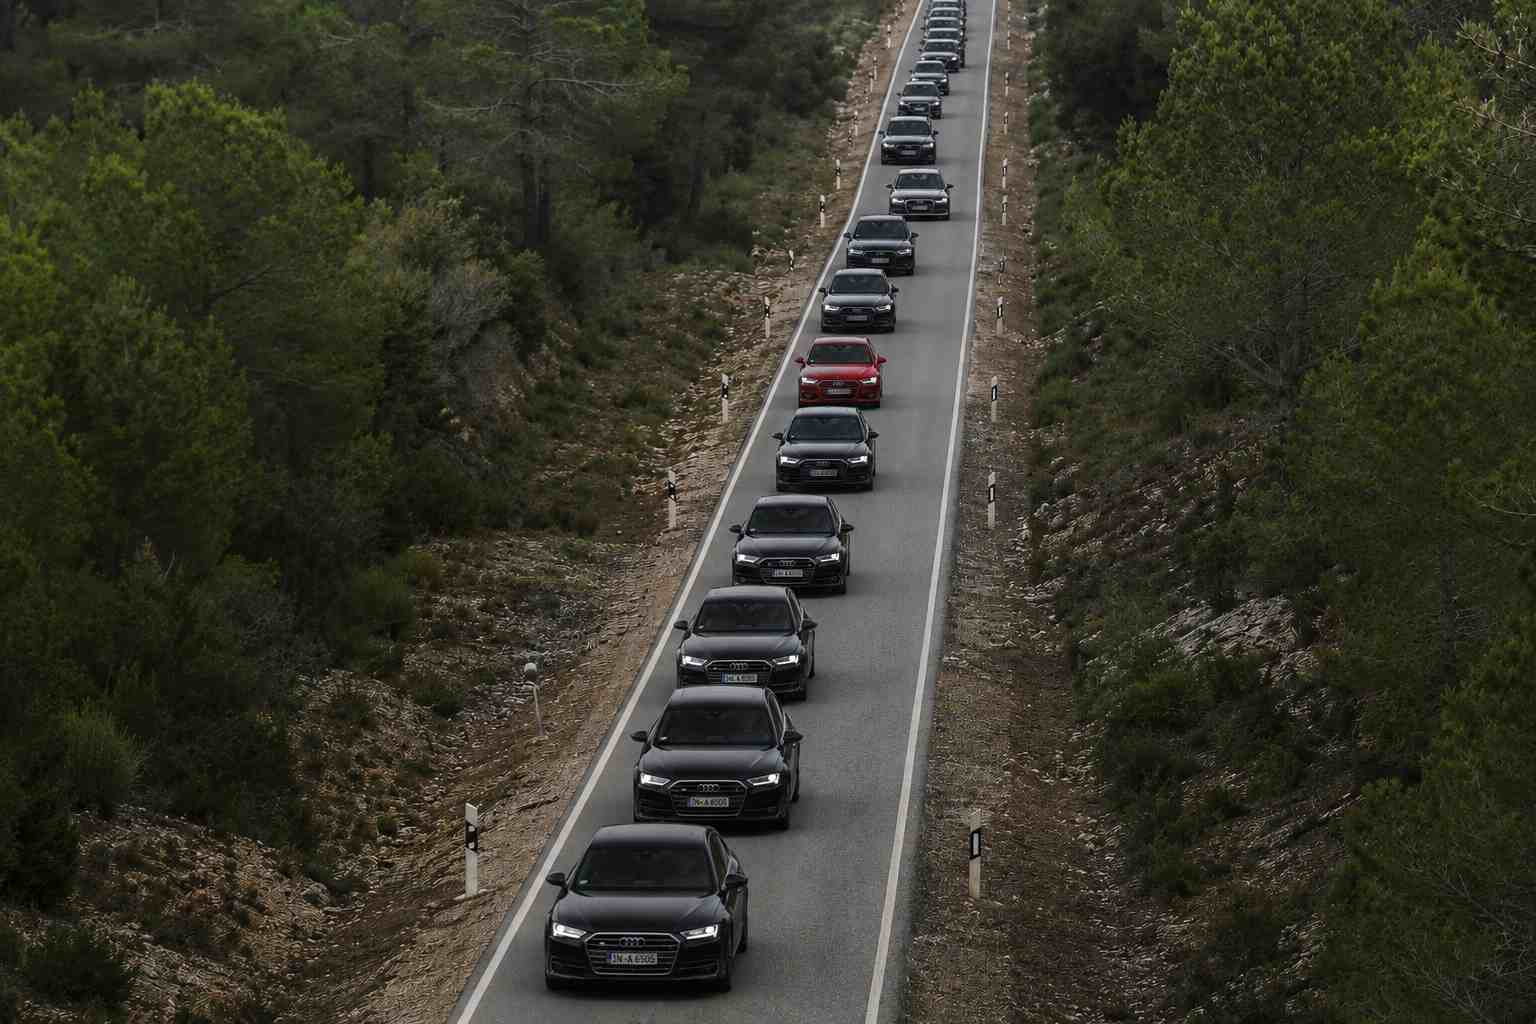</div>


### Verkehrssimulation 

In dieser Aufgabe soll eine mikroskopische Verkehrssimulation für Fahrzeuge auf einer Straße entwickelt werden. Die Fahrzeuge fahren alle in dieselbe Richtung. Es gibt keine Ampeln und keine Kreuzungen und nur eine Fahrspur, trotzdem können durch das Fahrverhalten der Fahrzeuge Staus entstehen.

Für die Simulation wird der Ort, die Geschwindigkeit und die Beschleunigung jedes einzelnen Fahrzeugs über der Zeit betrachtet. Dabei werden die Veränderungen in kleinen Zeitschritten `dt=0.1` s über einen Zeitraum `t_max = 600` s hinweg betrachtet.

Für die Simulation betrachten wir eine Straße der Länge `L=1200` m und `N=50` Fahrzeuge. Zur Vereinfachung der Simulation, wird außerdem angenommen, dass ein Fahrzeug beim Erreichen des Endes der Straße am Beginn der Straße wieder auftaucht. Das heißt, wir betrachten eine Ringstraße. Die maximale Geschwindigkeit der Fahrzeuge sei `v_max = 30` m/s.

### Aufgabe 1: Initialisierung der globalen Zustandsarrays

Die Arrays für die Positionen `x`, die Geschwindigkeiten `v` und die Beschleunigungen `a` enthalten die Daten für alle Fahrzeuge und alle Zeitschritte.

Implementieren Sie die Funktion `initialisiere_verkehr()`. Die Funktion soll die Arrays in der ersten Zeile mit passenden Startwerten füllen. Die Fahrzeuge starten näherungsweise gleichmäßig verteilt auf der Ringstraße. Dazu werden die Positionen der Fahrzeuge zunächst gleichmäßig auf der Ringstraße verteilt, sodass der Abstand zwischen zwei benachbarten Fahrzeugen genau `L/N` (also 24 m) beträgt. Anschließend wird jede Position zufällig um einen Betrag zwischen 0 und `max_start_stoerung = 8` m in Fahrtrichtung verschoben. Die Anfangsgeschwindigkeit ist für alle Fahrzeuge `v_max/3` und die Beschleunigung ist 0.

Alle restlichen Zeilen von `x, v, a` sollen mit dem Wert 0 gefüllt werden.

In [1]:
# notwendige Imports für die Aufgabe
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

# globale Simulationsparameter
N = 50                   # Anzahl der Fahrzeuge
dt = 0.1                 # s
t_max = 600.0            # s, 10 Minuten
t = np.arange(0, t_max, dt)
n_steps = len(t)         # Anzahl der Zeitschritte
L = 1200.0               # m, Länge der Ringstraße
v_max = 30.0             # m/s
max_start_stoerung = 8.0 # m, maximale zufällige Anfangsstörung

# globale Zustandsarrays
x = np.zeros((n_steps, N))
v = np.zeros((n_steps, N))
a = np.zeros((n_steps, N))

def initialisiere_verkehr():
    basis_positionen = np.arange(N) * (L/N)
    stoerung = np.random.uniform(0,max_start_stoerung,size = N)
    x[0, :] = (basis_positionen + stoerung) % L
    v[0, :] = v_max / 3
    a[0, :] = 0.0

initialisiere_verkehr()

In [2]:
# Hier sind Plausibilitäts-Tests:
initialisiere_verkehr()
x_gleichmaessig = np.linspace(0.0, L, N, endpoint=False)

assert np.all(np.abs(x[0] - x_gleichmaessig) <= max_start_stoerung)
assert np.allclose(v[0], v_max / 3)
assert np.allclose(a[0], 0.0)
assert np.allclose(x[1:], 0.0)
assert np.allclose(v[1:], 0.0)
assert np.allclose(a[1:], 0.0)


### Aufgabe 2: Modell der optimalen Geschwindigkeit

Für die Simulation wird das **Optimal Velocity Model** verwendet. Dabei wird davon ausgegangen, dass jedes Fahrzeug versucht, eine bestimmte Geschwindigkeit zu erreichen, die vom Abstand zum vorhergehenden Fahrzeug abhängt. Ist der Abstand groß, kann eine höhere Geschwindigkeit gefahren werden als bei kleinem Abstand. Die optimale Geschwindigkeit ist

$$
V_\mathrm{opt}(d,v)=v_\mathrm{max}\left(1-\exp\left[-\frac{\max(d-s_\mathrm{safe}(v),0)}{d_\mathrm{scale}}\right]\right)
$$

und hängt vom Sicherheitsabstand

$$
s_\mathrm{safe}(v)=s_0+T v
$$

ab. $s_0$ ist der Mindestabstand zwischen zwei Fahrzeugen und $T$ ist die zusätzliche Zeit zwischen der Passage von zwei Fahrzeugen. $d_\mathrm{scale}$ gibt an, wie stark sich die optimale Geschwindigkeit in Abhängigkeit vom Abstand ändert.

Implementieren Sie die Funktion `berechne_vopt(x_zeile, v_zeile)`, der Vektoren mit den momentanen Positionen und Geschwindigkeiten aller Fahrzeuge übergeben werden. Die Abstände zum vorausfahrenden Fahrzeug werden innerhalb der Funktion aus den Positionen abgeleitet. Fahrzeug `i+1` fährt vor Fahrzeug `i`; für das letzte Fahrzeug ist Fahrzeug `0` das vorausfahrende Fahrzeug. Verwenden Sie die Ringgeometrie mit der globalen Ringlänge `L`, sodass der Abstand immer positiv ist. Die Funktion soll die Geschwindigkeit für jedes Fahrzeug als Array zurückgeben.


In [3]:
# Modellparameter
s0 = 10.0            # m, Mindestabstand ohne separat modellierte Fahrzeuglaenge
T = 0.6              # s, Zeitluecke fuer geschwindigkeitsabhaengigen Sicherheitsabstand
d_scale = 10.0       # m, Skalenlaenge der Optimalgeschwindigkeit


def berechne_vopt(x_zeile, v_zeile):
    d = (np.roll(x_zeile, - 1) - x_zeile) % L
    s_safe = s0 + T * v_zeile
    v_opt = v_max * (1 - np.exp(-np.maximum(d - s_safe , 0) / d_scale))
    return v_opt

v_opt0 = berechne_vopt(x[0], v[0])
print(v_opt0[:5])

[14.2512842  18.18104632 16.02968593 12.90579907 19.59779319]


In [4]:
# Hier sind Plausibilitäts-Tests:
_vopt = berechne_vopt(np.array([0, 400, 800]), np.array([0, 0, 0]))
assert np.all(_vopt >= 0.0) and np.all(_vopt <= v_max)
_vopt = berechne_vopt(x[0], v[0])
assert _vopt.shape == (N,)

### Aufgabe 3: Einfluss des Abstands auf die optimale Geschwindigkeit

Untersuchen Sie nun mit `berechne_vopt`, wie sich die optimale Geschwindigkeit mit dem Abstand zum vorausfahrenden Fahrzeug verändert. Verwenden Sie dazu jeweils zwei Fahrzeuge: Fahrzeug 0 befindet sich bei `x=0`, Fahrzeug 1 bei `x=d`. Der Abstand von Fahrzeug 0 zum vorausfahrenden Fahrzeug ist dann genau `d`.

Stellen Sie `V_opt` für aktuelle Geschwindigkeiten von `0 m/s` und `15 m/s` als Funktion von `d` für Abstände zwischen 0 und 100 in einem gemeinsamen Diagramm dar. Beschriften Sie die Achsen und geben Sie dem Diagramm einen Titel und eine Legende! 

**Speichern Sie die Figur in der Variablen fig_vopt!**

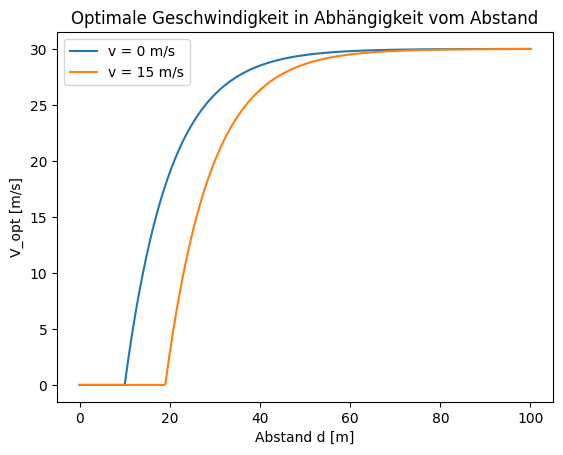

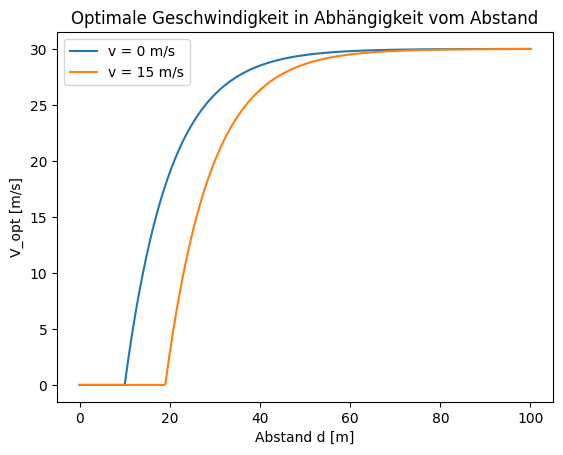

In [5]:
fig_vopt, ax_vopt = plt.subplots()
d_werte = np.linspace(0, 100, 500)
for v_akt in [0.0, 15.0]:
    v_opt_werte = np.array([
        berechne_vopt(np.array([0.0, d]), np.array([v_akt, v_akt]))[0]
        for d in d_werte
        ])
    ax_vopt.plot(d_werte, v_opt_werte, label=f"v = {v_akt:.0f} m/s")

ax_vopt.set_xlabel("Abstand d [m]")
ax_vopt.set_ylabel("V_opt [m/s]")
ax_vopt.set_title("Optimale Geschwindigkeit in Abhängigkeit vom Abstand")
ax_vopt.legend()

fig_vopt


In [6]:
# Hier sind Plausibilitäts-Tests:
_ax = fig_vopt.get_axes()[0]
_lines = [ln for ln in _ax.get_lines() if len(ln.get_xydata()) > 2]
assert len(_lines) >= 2
_xy = [ln.get_xydata().T for ln in _lines[-2:]]
assert all(np.isclose(xd[0], 0.0) and np.isclose(xd[-1], 100.0) for xd, _ in _xy)
assert any(np.isclose(yd[0], 0.0) and yd[-1] > yd[len(yd)//4] for _, yd in _xy)


In [7]:
# Einige weitere Plausibilitäts-Tests:
_yd = [yd for _, yd in _xy]
_idx_0 = int(np.argmax([yd[len(yd)//4] for yd in _yd]))
_y_plot_0 = _yd[_idx_0]
_y_plot_15 = _yd[1 - _idx_0]
assert _y_plot_15[len(_y_plot_15)//2] < _y_plot_0[len(_y_plot_0)//2]


### Aufgabe 4: Ein Simulationsschritt

Im Verlauf der Simulation wird in jedem Zeitschritt $k$ der Unterschied zwischen optimaler und momentaner Geschwindigkeit $v_k$ betrachtet und es wird angenommen, dass jedes Fahrzeug entsprechend beschleunigt oder verzögert, um die optimale Geschwindigkeit zu erreichen:

$$
a_k = \alpha\left(V_\mathrm{opt}(x_k,v_k)-v_k\right).
$$

Der Parameter $\alpha$ gibt dabei an, wie stark die Reaktion des Fahrzeugs (bzw. der Fahrerin) ist. Ein kleiner Wert bedeutet eine verhaltene Reaktion (bedachtsames Fahren), ein großer Wert bedeutet eine schnelle Reaktion ('sportliches' Fahren).

Implementieren Sie die Funktion `simuliere_schritt(k)`. Die Funktion soll für den Zeitschritt `k` die optimalen Geschwindigkeiten und Beschleunigungen $a_k$ berechnen und dann mit dem expliziten Euler-Verfahren die Zustände für den nächsten Zeitschritt eintragen:

$$
v_{k+1}=\max\left(0, v_k+\Delta t\,a_k\right)
$$

$$
x_{k+1}=\left(x_k+\Delta t\,v_k\right)\bmod L
$$

Die Beschleunigung soll auf das Intervall `[a_min, a_max]` begrenzt werden. Die Funktion soll keine Werte zurückgeben, sondern die globalen Arrays `x, v, a` aktualisieren. 

Führen Sie anschließend `simuliere_schritt(0)` aus!

In [8]:
# Modellparameter
alpha = 0.8          # 1/s, Reaktionsstaerke
a_min = -6.0         # m/s^2
a_max = 2.5          # m/s^2


def simuliere_schritt(k):
    v_opt = berechne_vopt(x[k], v[k])
    a_k = alpha * (v_opt - v[k])
    a_k = np.clip(a_k, a_min, a_max)    
    a[k] = a_k    
    v[k + 1] = np.maximum(0, v[k] + dt * a_k)
    x[k + 1] = (x[k] + dt * v[k]) % L
initialisiere_verkehr()
simuliere_schritt(0)


In [9]:
# Hier sind Plausibilitäts-Tests:
initialisiere_verkehr()
_x0 = x[0].copy()
_v0 = v[0].copy()
assert simuliere_schritt(0) is None
_vopt = berechne_vopt(_x0, _v0)
_d0 = np.mod(np.roll(_x0, -1) - _x0, L)
assert np.all(_d0 > 0)
assert np.allclose(x[1], (_x0 + dt * _v0) % L)
assert np.all(v[1] >= 0.0)


### Aufgabe 5: Simulation und Darstellung über der Zeit

Implementieren Sie die Funktion `simuliere_verkehr()`, die die Simulation für alle Zeitschritte durchführt. Die Funktion soll die globalen Arrays `x`, `v` und `a` vollständig füllen und keine Werte zurückgeben.

Stellen Sie die Geschwindigkeit der Fahrzeuge Nr. 0 und Nr. 25 sowie die mittlere Geschwindigkeit aller Fahrzeuge in einem Diagramm über der Zeit dar. Beschriften Sie die Achsen und geben Sie dem Diagramm einen Titel und eine Legende! 

**Speichern Sie die Figur in der Variablen fig_v_t!**

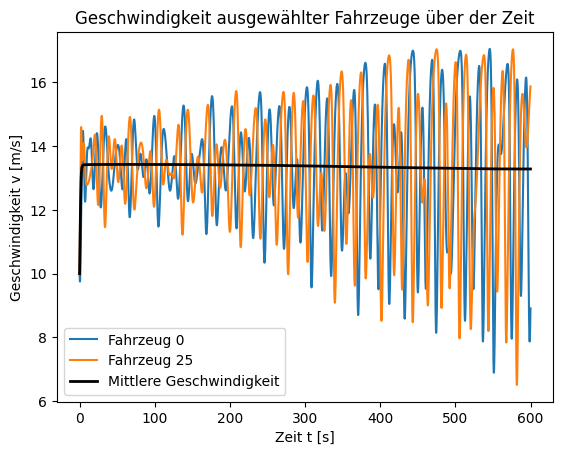

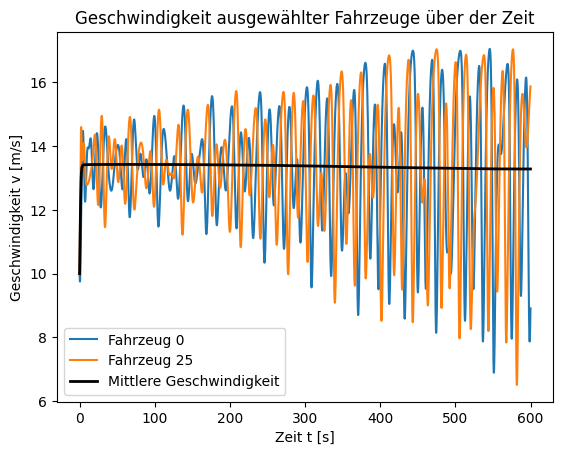

In [10]:
fig_v_t, ax_v_t = plt.subplots()

def simuliere_verkehr():
    for k in range(n_steps - 1):
        simuliere_schritt(k)

initialisiere_verkehr()
simuliere_verkehr()

ax_v_t.plot(t, v[:, 0], label="Fahrzeug 0")
ax_v_t.plot(t, v[:, 25], label="Fahrzeug 25")
ax_v_t.plot(t, v.mean(axis=1), label="Mittlere Geschwindigkeit", linewidth=2, color="black")

ax_v_t.set_xlabel("Zeit t [s]")
ax_v_t.set_ylabel("Geschwindigkeit v [m/s]")
ax_v_t.set_title("Geschwindigkeit ausgewählter Fahrzeuge über der Zeit")
ax_v_t.legend()

fig_v_t

In [11]:
# Hier sind Plausibilitäts-Tests:
assert simuliere_verkehr() is None
assert np.all(v >= 0.0)
assert np.all((x >= 0.0) & (x < L))
_d = np.array([np.mod(np.roll(xk, -1) - xk, L) for xk in x])
assert np.allclose(_d.sum(axis=1), L)
assert v[len(t) // 2:].std() > 0.5
_ax = fig_v_t.get_axes()[0]
_lines = [ln for ln in _ax.get_lines() if len(ln.get_xydata()) > 2]
assert len(_lines) >= 3


### Aufgabe 6: Darstellung der Stauwellen

Stellen Sie nun ein Raum-Zeit-Diagramm dar, in dem die Positionen der Fahrzeuge sichtbar werden. Verwenden Sie dazu ausgewählte Ergebnisse der Simulation alle 5 s (also bei 0, 5, 10, 15, 20, ... Sekunden). Stellen die Position auf der x-Achse und die Zeit auf der y-Achse dar. Alle Fahrzeuge sollen durch schwarze Punkte dargestellt werden, das Fahrzeug 0 soll durch rote Punkte markiert werden. Stauwellen sind darin als verdichtete Bereiche erkennbar. Die roten Punkte erlauben, die Position des Fahrzeugs 0 während der Fahrt zu verfolgen. Beschriften Sie die Achsen und geben Sie dem Diagramm einen Titel und eine Legende! 

**Speichern Sie die Figur in der Variablen fig_stau!**

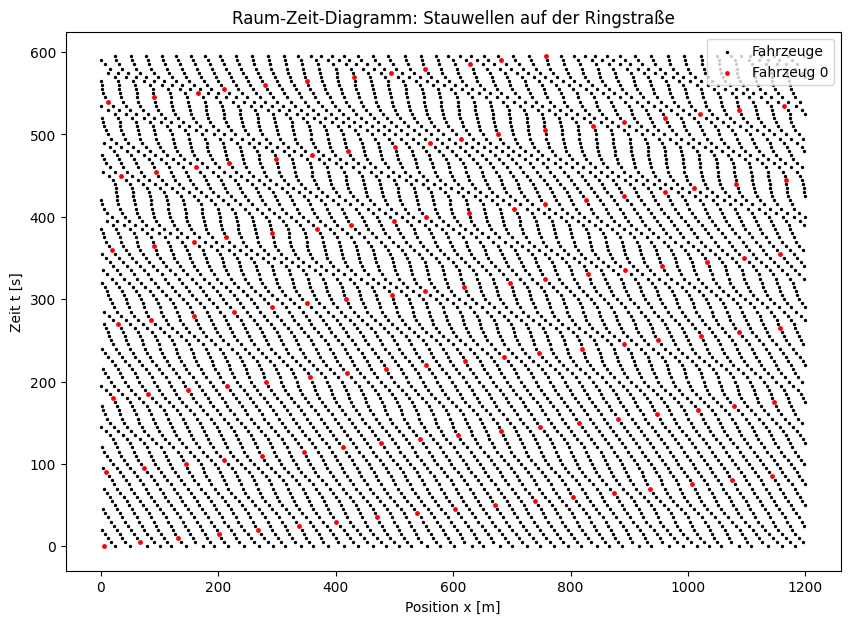

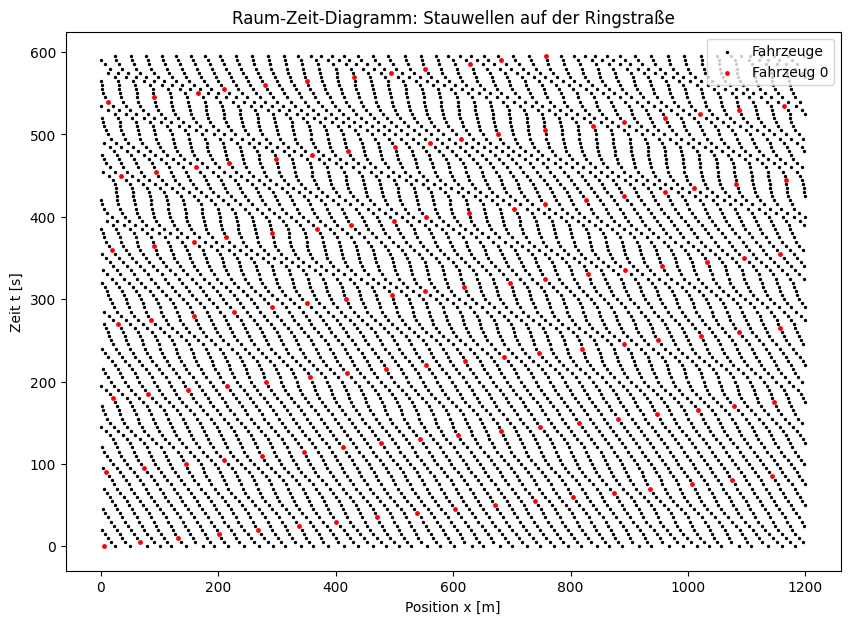

In [12]:
fig_stau, ax_stau = plt.subplots(figsize=(10, 7))

schritt_intervall = int(5.0 / dt)  # alle 5 s
indices = np.arange(0, n_steps, schritt_intervall)

# alle Fahrzeuge (schwarz)
x_sel = x[indices, :]
t_sel = t[indices]
t_matrix = np.repeat(t_sel[:, np.newaxis], N, axis=1)

ax_stau.scatter(x_sel, t_matrix, s=2, color="black", label="Fahrzeuge")

# Fahrzeug 0 (rot)
ax_stau.scatter(x_sel[:, 0], t_sel, s=6, color="red", label="Fahrzeug 0")

ax_stau.set_xlabel("Position x [m]")
ax_stau.set_ylabel("Zeit t [s]")
ax_stau.set_title("Raum-Zeit-Diagramm: Stauwellen auf der Ringstraße")
ax_stau.legend()

fig_stau

In [13]:
# Hier sind Plausibilitäts-Tests:
_ax = fig_stau.get_axes()[0]
assert len(_ax.collections) >= 2


In [14]:
# Einige weitere Plausibilitäts-Tests:
_punkte_alle = _ax.collections[-2].get_offsets()
assert _punkte_alle.shape[1] == 2
_punkte_rot = _ax.collections[-1].get_offsets()
_zeiten_rot = np.asarray(_punkte_rot[:, 1], dtype=float)
assert _punkte_rot.shape[0] == len(np.arange(0, len(t), int(5.0 / dt)))
assert np.allclose(np.diff(_zeiten_rot[:3]), 5.0)
_k_plot = np.arange(0, len(t), int(5.0 / dt))
assert np.allclose(np.sort(_punkte_rot[:, 0]), np.sort(x[_k_plot, 0]))

### Aufgabe 7: Einfluss der Reaktionsstärke auf den Verkehrsfluss

Zum Abschluss soll untersucht werden, wie der mittlere Verkehrsfluss von der Reaktionsstärke `alpha` abhängt. Der Verkehrsfluss ist

$$
q=\rho \cdot \bar v =\frac{N}{L} \bar v,
$$

wobei $\bar v$ die mittlere Geschwindigkeit aller Fahrzeuge während der gesamten Simulation ist. Weisen Sie dazu `alpha` Werte zwischen 0.5 und 1.0 zu und führen Sie die Simulation für jeden dieser Werte neu durch. Stellen Sie anschließend den Verkehrsfluss als Funktion von `alpha` dar. Berücksichtigen Sie für die Mittelwertbildung nur die letzten 3000 Schritte der Simulation.

Das Ergebnis zeigt, wie der Verkehrsfluss unter den hier gegebenen Bedingungen von der Reaktionsstärke der Fahrer abhängt. Beschriften Sie die Achsen und geben Sie dem Diagramm einen Titel und eine Legende! 

**Speichern Sie die Figur in der Variablen fig_fluss!**

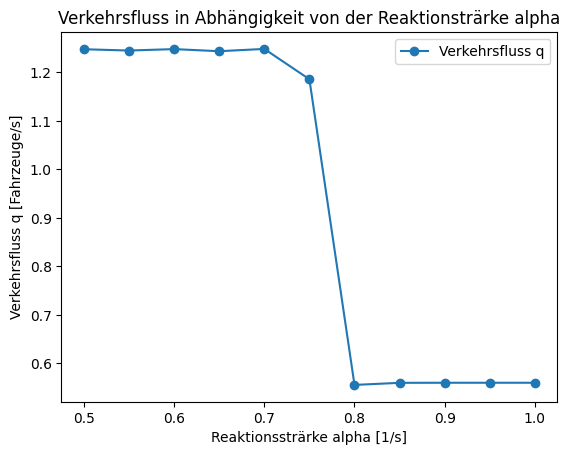

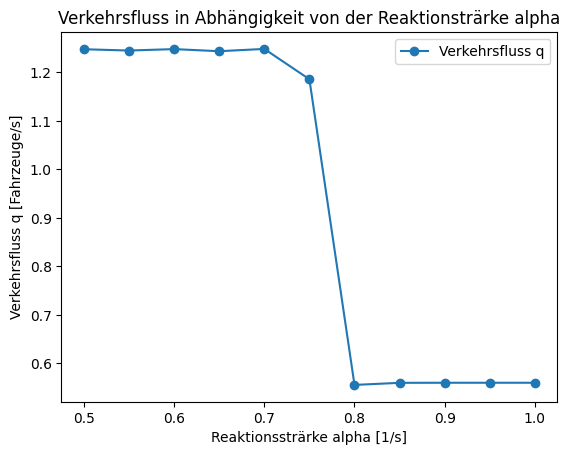

In [15]:
fig_fluss, ax_fluss = plt.subplots()
alpha_werte = np.linspace(0.5, 1.0, 11)

fluss_werte = np.zeros(len(alpha_werte))
for i,alpha_wert in enumerate(alpha_werte) :
    alpha = alpha_wert
    initialisiere_verkehr()
    simuliere_verkehr()
    v_mittel = v[-3000:, :].mean()
    fluss_werte[i] = (N / L) * v_mittel

ax_fluss.plot(alpha_werte, fluss_werte, marker ="o", label ="Verkehrsfluss q")
ax_fluss.set_xlabel("Reaktionssträrke alpha [1/s]") 
ax_fluss.set_ylabel("Verkehrsfluss q [Fahrzeuge/s]")
ax_fluss.set_title("Verkehrsfluss in Abhängigkeit von der Reaktionsträrke alpha")
ax_fluss.legend()
fig_fluss


In [16]:
# Hier sind Plausibilitäts-Tests:
_ax = fig_fluss.get_axes()[0]
_lines = [ln for ln in _ax.get_lines() if len(ln.get_xydata()) > 2]
assert len(_lines) >= 1


In [17]:
# Einige weitere Plausibilitäts-Tests:
_alpha_plot = np.asarray(_lines[-1].get_xdata(), dtype=float)
_fluss_plot = np.asarray(_lines[-1].get_ydata(), dtype=float)
assert np.isclose(_alpha_plot[0], 0.5), "alpha muss bei 0.5 beginnen"
assert np.isclose(_alpha_plot[-1], 1.0), "alpha muss bei 1.0 enden"
assert len(_alpha_plot) == 11, "es werden 11 alpha-Werte erwartet"
assert _fluss_plot.shape == _alpha_plot.shape, "x- und y-Daten müssen gleich lang sein"
assert np.all(np.diff(_alpha_plot) > 0.0), "alpha-Werte müssen aufsteigend sein"


Das hier verwendete Modell ist stark vereinfacht und kann ausgebaut werden, um beispielsweise verschiedene Fahrzeugtypen, verschiedenes Fahrverhalten usw. zu betrachten. So lassen sich sowohl Aussagen über Möglichkeiten zur Vermeidung von Staus gewinnen, als auch gut geeignete Steuerungsparameter für autonomes Fahren und Fahrassistenzsysteme untersuchen.
